# V05: OCI service hostname coverage

Record which of your selected OCI service endpoints can be configured and accessed through the workspace.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Inventory | Select actual resources you own. Possible coverage includes Autonomous Database, Streaming, OpenSearch, PostgreSQL, Data Flow interactive endpoints and Kafka endpoints. This is a test inventory, not a guarantee of automatic DNS insertion or a service-wide exception policy. |
| Route per service | Use each resource's real connection descriptor. Verify whether it needs an in-region service gateway, customer egress or a private route. Do not assume all selected services share a gateway or listener port. |
| DNS | Use actual resource FQDNs rather than probing only a service-zone root. Record saved workspace configuration and runtime results for each resource. |
| Security and service operation | Verify each service's firewall/NSG and authorization prerequisites and use a small supported read/query operation. Record unavailable fixtures as blocked coverage, not success. |
| Change control | Use owned test endpoints and restore only entries introduced for this coverage run. Record any additional support/configuration action required rather than assuming none. |


### Example network topology

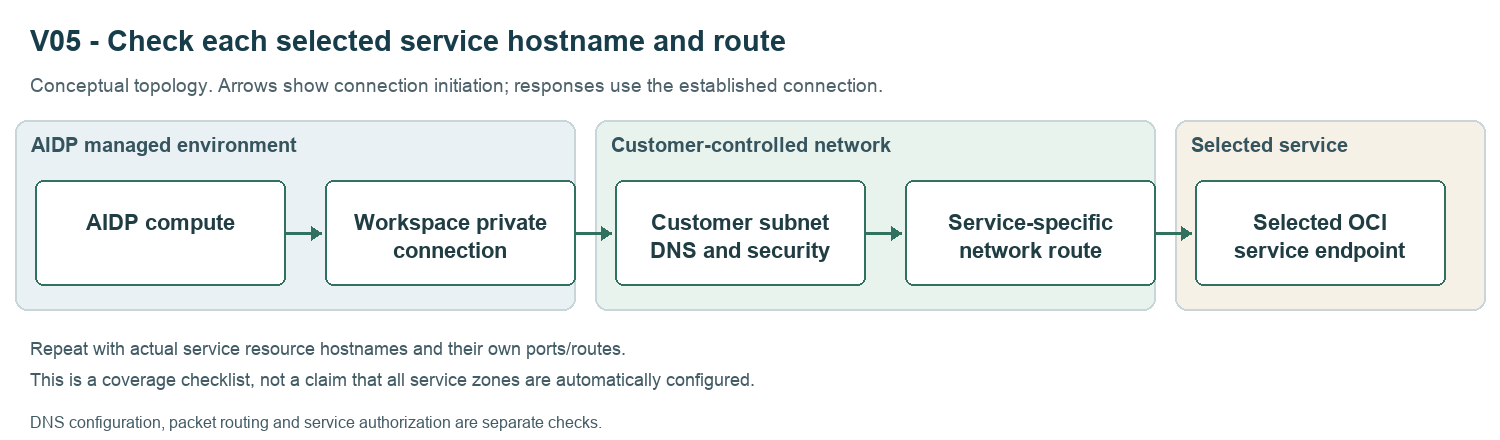

The diagram is illustrative; it does not prove the route taken by a request.


## Test procedure

1. Fill required_services and one actual endpoint record for each selected service.
2. Capture accepted/rejected FQDN operations and reopened saved configuration per host.
3. Perform each service's existing authenticated operation and reference its evidence.
4. Evaluate the recorded coverage, review endpoint scope, and restore the baseline.

**Acceptance:** Each selected endpoint has configuration and authenticated-operation evidence. Do not generalize an endpoint result to an entire DNS zone or all service instances.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V05': 'OCI service hostname coverage'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def evaluate_evidence(case, evidence):
    """Validate explicitly supplied Workbench snapshots; never modify Workbench.

    These assertions check recorded observations. External source-path, private
    endpoint and mTLS claims always require human evidence review.
    """
    result = {'case': case, 'utc': utc(), 'origin': 'supplied evidence', 'checks': {}}
    checks = result['checks']
    if not evidence.get('evidence_ref'):
        checks['evidence'] = {'status': 'BLOCKED', 'reason': 'Missing evidence artifact reference'}
        return result

    def test(name, condition):
        checks[name] = {'status': 'PASS' if condition else 'FAIL'}
    before = evidence.get('before')
    restored = evidence.get('restored')
    services = evidence.get('services', [])
    required = evidence.get('required_services', [])
    if not required or not services:
        checks['service_inventory'] = {'status': 'BLOCKED', 'reason': 'Select services and their actual resource hostnames'}
        return result
    for service in required:
        matches = [s for s in services if s.get('service') == service]
        test(service, len(matches) == 1 and bool(matches[0].get('hostname')) and (matches[0].get('configuration_accepted') is True) and (matches[0].get('functional') == 'PASS') and bool(matches[0].get('saved_config_ref')) and bool(matches[0].get('operation_evidence_ref')))
    checks['coverage_review'] = {'status': 'REVIEW_REQUIRED', 'reason': 'Review endpoint scope and observed configuration; no automatic service-wide claim'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V05'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


### Service observation format

Select your own required_services labels. Add one service record per selected resource using this shape. A missing fixture is blocked coverage. Accepted DNS configuration is not an authenticated read.


In [ ]:
SERVICE_RECORD_EXAMPLE = {"service": "", "hostname": "", "configuration_accepted": None, "saved_config_ref": None, "functional": None, "operation_evidence_ref": None, "additional_configuration_notes": ""}


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None, 'required_services': [], 'services': []}


In [ ]:
if RUN_EVIDENCE_CHECKS:
    observed = evaluate_evidence(CASE_ID, EVIDENCE)
    observed["acceptance"] = summarize(observed)
    RESULTS.append(observed)
    print(json.dumps(observed, indent=2))
else:
    print("Evidence assertions NOT_RUN; capture real observations first.")


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)
- [sgw](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
